In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, Matern
from scipy.stats import norm
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

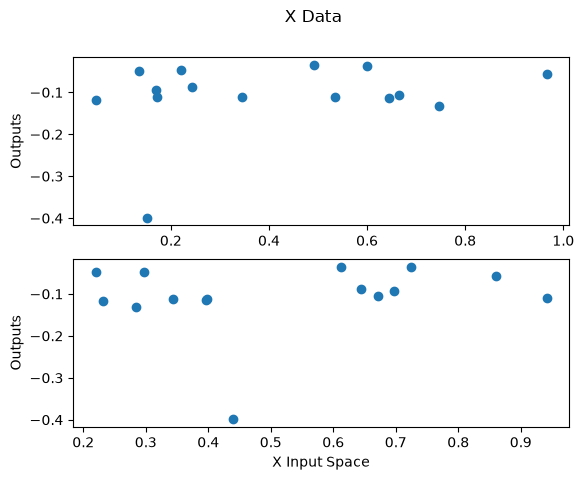

In [ ]:
X = np.load('..\Function_3_Data\Week_1_Data/initial_inputs.npy')
Y = np.load('..\Function_3_Data\Week_1_Data/initial_outputs.npy')
fig, (ax1, ax2) = plt.subplots(2, 1)
fig.suptitle('X Data')
ax1.scatter(X[:,0], Y)
ax1.set_ylabel('Outputs')
ax2.scatter(X[:,1], Y)
ax2.set_xlabel('X Input Space')
ax2.set_ylabel('Outputs')
plt.show()

In [15]:
length_scale_vector = np.ones(X.shape[1])
kernel = ConstantKernel(1.0) * RBF(length_scale=length_scale_vector)
gp = GaussianProcessRegressor(kernel=kernel, alpha=1e-6, n_restarts_optimizer=10)
gp.fit(X, Y)

,kernel,"1**2 * RBF(le...ale=[1, 1, 1])"
,alpha,1e-06
,optimizer,'fmin_l_bfgs_b'
,n_restarts_optimizer,10
,normalize_y,False
,copy_X_train,True
,n_targets,None
,random_state,None
,kernel__k1,1**2
,kernel__k2,"RBF(length_scale=[1, 1, 1])"
,kernel__k1__constant_value,1.0


In [16]:
def upper_confidence_bound(mu, sigma, kappa=2.0):
    """
    Upper Confidence Bound (UCB) acquisition function.
    
    UCB = mean + kappa * std
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation
    kappa : exploration parameter (higher = more exploration)
    """
    return mu + kappa * sigma


def expected_improvement(mu, sigma, y_best, xi=0.01):
    """
    Expected Improvement (EI) acquisition function.
    
    EI = E[max(f(x) - f(x_best), 0)]
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation  
    y_best : best observed value so far
    xi : exploration parameter
    """
    with np.errstate(divide='warn'):
        improvement = mu - y_best - xi
        Z = improvement / sigma
        ei = improvement * norm.cdf(Z) + sigma * norm.pdf(Z)
        ei[sigma == 0.0] = 0.0
    return ei


In [17]:
def acq_objective(X):
    X = X.reshape(1, -1)
    mu, sigma = gp.predict(X, return_std=True)
               
    if acquisition == 'ei':
        acq_val = expected_improvement(mu, sigma, Y.max())
    else:
        acq_val = upper_confidence_bound(mu, sigma, kappa=2)
           
    return -acq_val  # Negative because we use the 'minimize' function later

In [19]:
acquisition='e1'
n_dims=X.shape[1]
bounds = [(0, 1) for _ in range(n_dims)]
best_acq = np.inf
X_next = None

bounds = [(0, 1) for _ in range(n_dims)]
for _ in range(10):  # Multiple random starts
    x0 = np.random.uniform(0, 1, n_dims)
    result = minimize(acq_objective, x0, bounds=bounds, method='L-BFGS-B')
    if result.fun < best_acq:
        best_acq = result.fun
        X_next = result.x

X_next

array([0.878516, 0.920106, 0.666725])